In [62]:
import numpy as np
import pandas as pd
import sqlite3  # swap for your actual connection (SQLAlchemy engine, etc.)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import re

conn = sqlite3.connect('../data/finance.db')

In [6]:
pd.read_sql(
    "SELECT interval, source, COUNT(*) AS n, COUNT(DISTINCT ticker) AS tickers, "
    "MIN(datetime) AS first, MAX(datetime) AS last "
    "FROM price_history GROUP BY interval, source",
    conn,
)

,interval,source,n,tickers,first,last
0,15m,yfinance,572,1,2026-09-10 09:30:00-0400,2026-10-09 15:45:00-0400
1,1d,yfinance,2948587,503,2000-01-03,2026-10-08
2,5m,yfinance,1716,1,2026-09-10 09:30:00-0400,2026-10-09 15:55:00-0400


In [13]:
# Top 10 stock tickers categorized by GICS sectors
sector_tickers = {
    "Technology": [
        "NVDA", "AAPL", "MSFT", "AVGO", "ORCL", 
        "AMD", "QCOM", "INTC", "CRM", "ADBE"
    ],
    "Communication_Services": [
        "GOOGL", "META", "NFLX", "TMUS", "DIS", 
        "VZ", "T", "CMCSA", "CHTR", "WBD"
    ],
    "Consumer_Discretionary": [
        "AMZN", "TSLA", "HD", "MCD", "NKE", 
        "BKNG", "LOW", "TJX", "SBUX", "CMG"
    ],
    "Financials": [
        "BRK-B", "JPM", "V", "MA", "BAC", 
        "WFC", "GS", "MS", "BLK", "C"
    ],
    "Health_Care": [
        "LLY", "JNJ", "UNH", "ABBV", "MRK", 
        "TMO", "ABT", "PFE", "DHR", "AMGN"
    ],
    "Consumer_Staples": [
        "WMT", "COST", "PG", "KO", "PEP", 
        "PM", "MDLZ", "MO", "CL", "TGT"
    ],
    "Industrials": [
        "GE", "CAT", "RTX", "HON", "UNP", 
        "BA", "LMT", "UPS", "FDX", "GD"
    ],
    "Energy": [
        "XOM", "CVX", "COP", "MPC", "SLB", 
        "EOG", "PSX", "VLO", "OXY"
    ],
    "Materials": [
        "LIN", "SHW", "FCX", "NEM", "APD", 
        "NUE", "DOW", "ECL", "DD", "PPG"
    ],
    "Utilities": [
        "NEE", "SO", "DUK", "CEG", "SRE", 
        "AEP", "D", "EXC", "XEL", "PCG"
    ],
    "Real_Estate": [
        "PLD", "AMT", "EQIX", "CCI", "PSA", 
        "DLR", "O", "WELL", "SPG", "VICI"
    ]
}

all_tickers = [ticker for tickers in sector_tickers.values() for ticker in tickers]

In [63]:
def parse_lookback(period):
    """Convert a period spec into a pandas DateOffset.

    Parameters
    ----------
    period : str or pandas.DateOffset
        Either a string made of an integer and a unit (``"y"`` for years,
        ``"m"`` for months, ``"w"`` for weeks, ``"d"`` for days), such as
        ``"2y"`` or ``"18m"``, or a ready-made ``pandas.DateOffset``
        (for example ``pd.DateOffset(years=1, months=6)``).

    Returns
    -------
    pandas.DateOffset
        The equivalent offset.

    Raises
    ------
    ValueError
        If a string does not match the expected format.
    """
    

    
    if isinstance(period, pd.DateOffset):
        return period
    match = re.fullmatch(r"\s*(\d+)\s*([ymwd])\s*", str(period).lower())
    if not match:
        raise ValueError(f"Can't parse lookback {period!r}; use e.g. '2y', '6m', '90d'.")
    n, unit = int(match.group(1)), match.group(2)
    keyword = {"y": "years", "m": "months", "w": "weeks", "d": "days"}[unit]
    return pd.DateOffset(**{keyword: n})

In [ ]:
def regular_hours_only(prices, tz="America/New_York", start="09:30", end="16:00"):
    """Keep only bars that start within the regular trading session.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices`` for an intraday interval, with a
        timezone-naive ``date`` column holding UTC timestamps.
    tz : str, optional
        Exchange time zone. Default is ``"America/New_York"``.
    start : str, optional
        Session open as ``"HH:MM"`` in exchange time. Default is
        ``"09:30"``.
    end : str, optional
        Session close as ``"HH:MM"`` in exchange time. Bars starting at
        or after this time are dropped. Default is ``"16:00"``.

    Returns
    -------
    pandas.DataFrame
        Rows whose bar start time falls inside the session, or the input
        unchanged if it contains only daily-or-longer bars.
    """
    if (prices["date"] == prices["date"].dt.normalize()).all():
        return prices
    
    local = prices["date"].dt.tz_localize("UTC").dt.tz_convert(tz)
    minutes = local.dt.hour * 60 + local.dt.minute

    def to_minutes(hhmm):
        h, m = map(int, hhmm.split(":"))
        return h * 60 + m

    mask = (minutes >= to_minutes(start)) & (minutes < to_minutes(end))
    return prices[mask].reset_index(drop=True)

In [64]:
def load_prices(conn, interval="1d", period=None, tickers=None, source=None):
    """Load price history for one bar interval from the database.

    Parameters
    ----------
    conn : sqlite3.Connection
        Open connection to the project database.
    interval : str, optional
        Bar interval to select, matching the ``interval`` column.
        Default is ``"1d"``.
    period : str, pandas.DateOffset, or None, optional
        If given, keep only the most recent span of data, measured back
        from the latest date in the table. See ``parse_lookback`` for
        accepted formats. Default is None (all history).
    tickers : list of str
        Tickers to keep. Case-insensitive.
    source : str or None, optional
        Data source to select, matching the ``source`` column. If None,
        no source filter is applied, so make sure only one source has
        data for each ticker and date.

    Returns
    -------
    pandas.DataFrame
        Columns ``ticker``, ``date``, ``close``, ``volume``, sorted by
        ticker and date.
    """
    
    query = (
        "SELECT ticker, datetime, Close AS close, Volume AS volume "
        "FROM price_history WHERE interval = ?"
    )
    params = [interval]
    if source is not None:
        query += " AND source = ?"
        params.append(source)
    
    df = pd.read_sql(query, conn, params=params)
    dt = pd.to_datetime(df["datetime"], utc=True).dt.tz_localize(None)
    intraday = interval.lower().endswith(("m", "h")) 
    df["date"] = dt if intraday else dt.dt.normalize()
    df = df.drop(columns="datetime")
    
    if period is not None:
        cutoff = df["date"].max() - parse_lookback(period)
        df = df[df["date"] >= cutoff]
    
    if tickers is not None:
        wanted = [t.upper() for t in tickers]
        missing = sorted(set(wanted) - set(df["ticker"].str.upper()))
        if missing:
            print(f"Not in database, skipped: {missing}")
        mask = df["ticker"].str.upper().isin(wanted)
        df = df[mask].reset_index(drop=True)

    dupes = df.duplicated(["ticker", "date"]).sum()
    if dupes:
        raise ValueError(f"{dupes} duplicate ticker/date rows; filter by source.")

    return df.sort_values(["ticker", "date"]).reset_index(drop=True)[
        ["ticker", "date", "close", "volume"]
    ]


prices = load_prices(conn, interval="1d", period="6m", source=None)  # adjust values

#prices = regular_hours_only(load_prices(conn, interval="15m", period="6m"))

prices.head()

,ticker,date,close,volume
0,A,2026-04-08,116.695541,1384600
1,A,2026-04-09,115.168480,1218700
2,A,2026-04-10,114.839111,1033200
3,A,2026-04-13,117.274429,1795600
4,A,2026-04-14,120.158882,2676900


In [65]:
FEATURES = ["ret_1", "ret_5", "ret_20", "vol_20", "ma_ratio", "volume_chg"]


def build_features(prices, horizon=5):
    """Build lagged-return features and a forward-direction target.

    All features use only information available at each row's date.
    The target is whether the close ``horizon`` days ahead is higher
    than today's close.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices``.
    horizon : int, optional
        Number of trading days ahead to predict. Default is 5.

    Returns
    -------
    pandas.DataFrame
        Feature columns, ``target`` (0 or 1), ``ticker`` and ``date``,
        with rows containing NaNs dropped.
    """
    g = prices.groupby("ticker", group_keys=False)
    out = prices.copy()

    daily_ret = g["close"].pct_change()
    out["ret_1"] = daily_ret
    out["ret_5"] = g["close"].pct_change(5)
    out["ret_20"] = g["close"].pct_change(20)
    out["vol_20"] = daily_ret.groupby(out["ticker"]).transform(
        lambda s: s.rolling(20).std()
    )
    ma_50 = g["close"].transform(lambda s: s.rolling(50).mean())
    out["ma_ratio"] = out["close"] / ma_50
    out["volume_chg"] = g["volume"].pct_change(5)

    fwd = g["close"].shift(-horizon) / out["close"] - 1
    out["target"] = (fwd > 0).astype(int)
    out.loc[fwd.isna(), "target"] = np.nan

    out = out.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES + ["target"])
    out["target"] = out["target"].astype(int)
    return out[["ticker", "date", *FEATURES, "target"]]


HORIZON = 5
data = build_features(prices, horizon=HORIZON)
print(data.shape, data["target"].mean())

(33983, 9) 0.4901274166495012


In [66]:
def walk_forward_scores(data, model, n_splits=5, horizon=5):
    """Evaluate a classifier with expanding-window splits over dates.

    Splitting is done on unique dates (not rows) so every ticker on a
    given day lands in the same fold. A gap of ``horizon`` days between
    train and test prevents the forward-looking target from leaking.

    Parameters
    ----------
    data : pandas.DataFrame
        Output of ``build_features``.
    model : sklearn.base.BaseEstimator
        Unfitted classifier supporting ``predict_proba``.
    n_splits : int, optional
        Number of walk-forward folds. Default is 5.
    horizon : int, optional
        Gap (in trading days) between train and test. Default is 5.

    Returns
    -------
    pandas.DataFrame
        Per-fold accuracy, ROC AUC, and majority-class baseline accuracy.
    """
    dates = np.sort(data["date"].unique())
    fold_edges = np.array_split(dates[len(dates) // 2:], n_splits)
    rows = []
    for i, test_dates in enumerate(fold_edges):
        test_start = test_dates[0]
        train_end_idx = np.searchsorted(dates, test_start) - horizon
        train = data[data["date"].isin(dates[:train_end_idx])]
        test = data[data["date"].isin(test_dates)]

        model.fit(train[FEATURES], train["target"])
        proba = model.predict_proba(test[FEATURES])[:, 1]
        base = max(train["target"].mean(), 1 - train["target"].mean())
        rows.append(
            {
                "fold": i,
                "accuracy": accuracy_score(test["target"], proba > 0.5),
                "auc": roc_auc_score(test["target"], proba),
                "baseline_acc": max(test["target"].mean(), 1 - test["target"].mean()),
            }
        )
    return pd.DataFrame(rows)


models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "rf": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=50, n_jobs=-1, random_state=0
    ),
}

for name, m in models.items():
    res = walk_forward_scores(data, m, horizon=HORIZON)
    print(name)
    print(res.round(3))
    print(res[["accuracy", "auc", "baseline_acc"]].mean().round(3), "\n")

logreg
   fold  accuracy    auc  baseline_acc
0     0     0.490  0.492         0.518
1     1     0.379  0.506         0.642
2     2     0.333  0.496         0.691
3     3     0.391  0.468         0.619
4     4     0.533  0.548         0.561
accuracy        0.425
auc             0.502
baseline_acc    0.606
dtype: float64 

rf
   fold  accuracy    auc  baseline_acc
0     0     0.506  0.547         0.518
1     1     0.421  0.522         0.642
2     2     0.447  0.538         0.691
3     3     0.504  0.526         0.619
4     4     0.552  0.537         0.561
accuracy        0.486
auc             0.534
baseline_acc    0.606
dtype: float64 



In [67]:
def stock_profiles(prices):
    """Summarize each ticker with a few return statistics.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices`` with columns ``ticker``, ``date``,
        ``close``.

    Returns
    -------
    pandas.DataFrame
        One row per ticker with columns ``avg_return`` (mean daily
        return), ``volatility`` (std of daily returns), and ``beta``
        (how strongly the stock moves with the average stock).
    """
    close = prices.pivot(index="date", columns="ticker", values="close")
    rets = close.pct_change().dropna(how="all")
    market = rets.mean(axis=1)  # the average stock each day

    profiles = pd.DataFrame(
        {
            "avg_return": rets.mean(),
            "volatility": rets.std(),
            "beta": rets.apply(lambda s: s.cov(market) / market.var()),
        }
    )
    return profiles.dropna()


profiles = stock_profiles(prices)
profiles.describe().round(4)

,avg_return,volatility,beta
count,503.0000,503.0000,503.0000
mean,0.0007,0.0231,1.0238
std,0.0023,0.0122,0.7442
min,-0.0047,0.0023,-1.4845
25%,-0.0006,0.0159,0.5872
50%,0.0003,0.0203,0.9955
75%,0.0014,0.0267,1.4476
max,0.0188,0.1699,5.1128


In [76]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


def cluster_stocks(profiles, n_clusters=4):
    """Group tickers into clusters based on their profile statistics.

    Parameters
    ----------
    profiles : pandas.DataFrame
        Output of ``stock_profiles``.
    n_clusters : int, optional
        Number of groups to find. Default is 4.

    Returns
    -------
    pandas.Series
        Cluster label for each ticker, indexed by ticker.
    """
    scaled = StandardScaler().fit_transform(profiles)  # put columns on equal footing
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
    return pd.Series(km.fit_predict(scaled), index=profiles.index, name="cluster")


profiles["cluster"] = cluster_stocks(profiles, n_clusters=8)
profiles.groupby("cluster").agg(["mean", "count"]).round(8)

avg_return       volatility            beta      
              mean count       mean count      mean count
cluster                                                  
0         0.008028    15   0.052211    15  1.188595    15
1         0.000859   151   0.018019   151  0.839029   151
2         0.001028   111   0.025423   111  1.649236   111
3         0.018843     1   0.169904     1  5.112821     1
4        -0.001661    64   0.026690    64  1.636272    64
5        -0.000793   107   0.015464   107  0.462268   107
6         0.000757    21   0.022147    21 -0.836875    21
7         0.003708    33   0.040004    33  1.383485    33

In [77]:
mask = profiles.index.isin(all_tickers)   # boolean array, one entry per row
sub_profiles = profiles[mask]

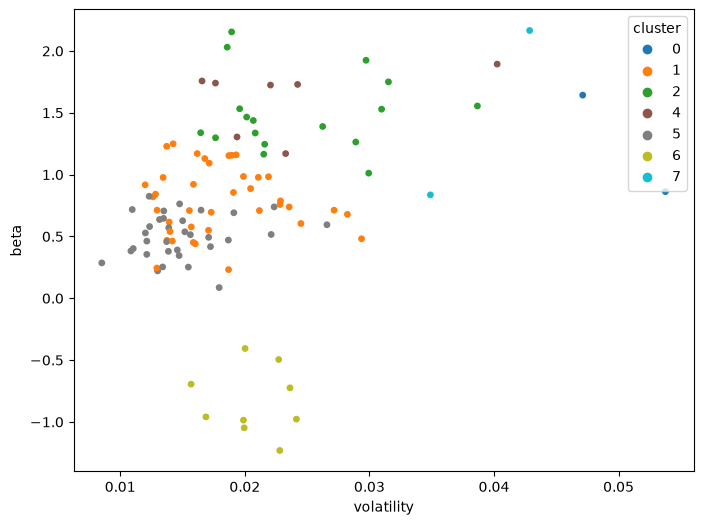

0 ['AMD', 'INTC']
1 ['AAPL', 'ABBV', 'ABT', 'AMGN', 'AMT', 'AMZN', 'AVGO', 'BAC', 'C', 'CL']
2 ['ADBE', 'BLK', 'CAT', 'CEG', 'DD', 'FCX', 'FDX', 'GE', 'GOOGL', 'GS']
4 ['BA', 'BKNG', 'CHTR', 'CMCSA', 'HD', 'LOW', 'NKE']
5 ['AEP', 'APD', 'BRK-B', 'CCI', 'COST', 'D', 'DUK', 'EXC', 'GD', 'JNJ']
6 ['COP', 'CVX', 'DOW', 'EOG', 'MPC', 'OXY', 'PSX', 'VLO', 'XOM']
7 ['CRM', 'QCOM']


In [82]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
scatter = (
    ax.scatter(sub_profiles["volatility"], sub_profiles["beta"], c=sub_profiles["cluster"], cmap="tab10", s=15)
)
# scatter = (
#     ax.scatter(profiles["volatility"], profiles["beta"], c=profiles["cluster"], cmap="tab10", s=15)
# )
ax.set_xlabel("volatility")
ax.set_ylabel("beta")
ax.legend(*scatter.legend_elements(), title="cluster")
plt.show()

for c in sorted(sub_profiles["cluster"].unique()):
    print(c, list(sub_profiles[sub_profiles["cluster"] == c].index[:10]))

In [74]:
for c in sorted(profiles["cluster"].unique()):
    print(c, list(profiles[profiles["cluster"] == c].index[:10]))

0 ['A', 'ABNB', 'ACN', 'ADBE', 'ADI', 'ADSK', 'AKAM', 'ALB', 'ALGN', 'ALLE']
1 ['AAPL', 'ABBV', 'ABT', 'ACGL', 'ADM', 'ADP', 'AEE', 'AEP', 'AES', 'AFL']
2 ['MRNA']
3 ['AMAT', 'AMD', 'ANET', 'BE', 'CNC', 'COHR', 'COIN', 'CRL', 'CRM', 'CRWD']


KeyError: 'AAPL'